<a href="https://colab.research.google.com/github/Isabella-de-Lima/python_sis_26_2/blob/isabella_lima_2_bimestre/aula_12/isabella_lima_aula12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# AULA 12 | ATIVIDADE 01 | Relatório em Planilha Inventário de Servidores

# Você é responsável pela gestão de ativos de TI e precisa gerar uma planilha
# com o inventário dos servidores virtuais para a auditoria mensal.

# Requisitos:
# *Crie scripts em Python que executem as etapas a seguir:

# Etapa 1: Instalação.
# Instale e importe a biblioteca openpyxl seguindo a PEP 8.

%pip install -q openpyxl

from openpyxl import Workbook
from openpyxl.styles import PatternFill

# Etapa 2: Crie uma planilha.
# Crie uma pasta de trabalho (planilha) com uma aba para o servidores.
# Adicione um cabeçalho: Ex: "Hostname", "IP", "Memória (GB)", "Uso de Disco (%)", "Status".

planilha = Workbook()
aba = planilha.active
aba.title = "Servidores"

aba.append([
    "Hostname", "IP", "Memória (GB)", "Uso de Disco (%)", "Status"
])

# Etapa 3: Inserção de dados.
# Insira pelo menos 4 servidores com dados simulados.

servidores = [
    ["servidor_web", "192.168.1.10", 8, 65, "Ativo"],
    ["servidor_banco", "192.168.1.20", 16, 85, "Ativo"],
    ["servidor_backup", "192.168.1.30", 32, 92, "Ativo"],
    ["servidor_teste", "192.168.1.40", 4, 80, "Inativo"],
]

for servidor in servidores:
    aba.append(servidor)

# Etapa 4: Avisos.
# Se o Uso de Disco (%) for maior ou igual a 80%, defina a cor da célula ou
# exiba um alerta no terminal informando que o servidor precisa de expansão de armazenamento.
# Salve o arquivo.

cor_alerta = PatternFill(
    start_color="FFFF00",
    end_color="FFFF00",
    fill_type="solid",
)

print("\n📋 INVENTÁRIO DE SERVIDORES\n")

for linha in aba.iter_rows(min_row=2):
    hostname = linha[0].value
    ip = linha[1].value
    memoria = linha[2].value
    uso_disco = linha[3].value
    status = linha[4].value

    print(f"🖥️ Servidor: {hostname}")
    print(f"IP: {ip}")
    print(f"Memória: {memoria} GB")
    print(f"Uso de disco: {uso_disco}%")
    print(f"Status: {status}")

    if uso_disco >= 80:
        linha[3].fill = cor_alerta
        print("⚠️ Precisa de expansão de armazenamento.")

    print()

nome_arquivo = "isabella_lima_aula12_ex1.xlsx"
planilha.save(nome_arquivo)

print("✅ PLANILHA SALVA COM SUCESSO")
print(f"Arquivo: {nome_arquivo}")




📋 INVENTÁRIO DE SERVIDORES

🖥️ Servidor: servidor_web
IP: 192.168.1.10
Memória: 8 GB
Uso de disco: 65%
Status: Ativo

🖥️ Servidor: servidor_banco
IP: 192.168.1.20
Memória: 16 GB
Uso de disco: 85%
Status: Ativo
⚠️ Precisa de expansão de armazenamento.

🖥️ Servidor: servidor_backup
IP: 192.168.1.30
Memória: 32 GB
Uso de disco: 92%
Status: Ativo
⚠️ Precisa de expansão de armazenamento.

🖥️ Servidor: servidor_teste
IP: 192.168.1.40
Memória: 4 GB
Uso de disco: 80%
Status: Inativo
⚠️ Precisa de expansão de armazenamento.

✅ PLANILHA SALVA COM SUCESSO
Arquivo: isabella_lima_aula12_ex1.xlsx


In [8]:
# AULA 12 | ATIVIDADE 02 | Conversor de Log para Planilha Arquivo de texto para excel

# Na aula anterior, trabalhamos com o arquivo de texto log.txt
# Precisamos converter essas informações brutas em uma planilha Excel para facilitar a visualização gerencial. .

# Requisitos:
# *Crie scripts em Python que executem as etapas a seguir:

from openpyxl import Workbook

# Etapa 1: log.txt.
# Abra o arquivo log.txt utilizando o bloco with e trate possíveis exceções com try/except (FileNotFoundError).

try:
    with open("log.txt", "r", encoding="utf-8") as arquivo:
        linhas_log = arquivo.readlines()
except FileNotFoundError:
    print("⚠️ Arquivo log.txt não encontrado. Envie o arquivo para o Colab.")
else:
    print("✅ Arquivo log.txt lido com sucesso.\n")

# Etapa 2: Extração de dados.
# Para cada linha de log, extraia o nível do evento (INFO, AVISO, ERRO).

eventos = []

for linha in linhas_log:
    partes = linha.strip().split(" - ", 2)

    if len(partes) == 3:
        data_hora, tipo_evento, mensagem = partes
        eventos.append([data_hora, tipo_evento, mensagem])

# Etapa 3: Criação de Planilha
# Crie uma nova planilha auditoria_logs.xlsx contendo as colunas do log: Data/Hora, Tipo de Evento e Mensagem.

planilha = Workbook()
aba = planilha.active
aba.title = "Logs"
aba.append(["Data/Hora", "Tipo de Evento", "Mensagem"])

# Etapa 4: Salvando.
# Preencha a planilha e salve-a no diretório de execução.

for evento in eventos:
    aba.append(evento)

nome_arquivo = "auditoria_logs.xlsx"
planilha.save(nome_arquivo)

print("✅ PLANILHA SALVA COM SUCESSO")
print(f"Arquivo: {nome_arquivo}")
print(f"Eventos registrados: {len(eventos)}")

✅ Arquivo log.txt lido com sucesso.

✅ PLANILHA SALVA COM SUCESSO
Arquivo: auditoria_logs.xlsx
Eventos registrados: 6


📋 RESUMO DA TELEMETRIA

Quantidade de medições: 5
Consumo médio de CPU: 14.98
Consumo médio de RAM: 10.06



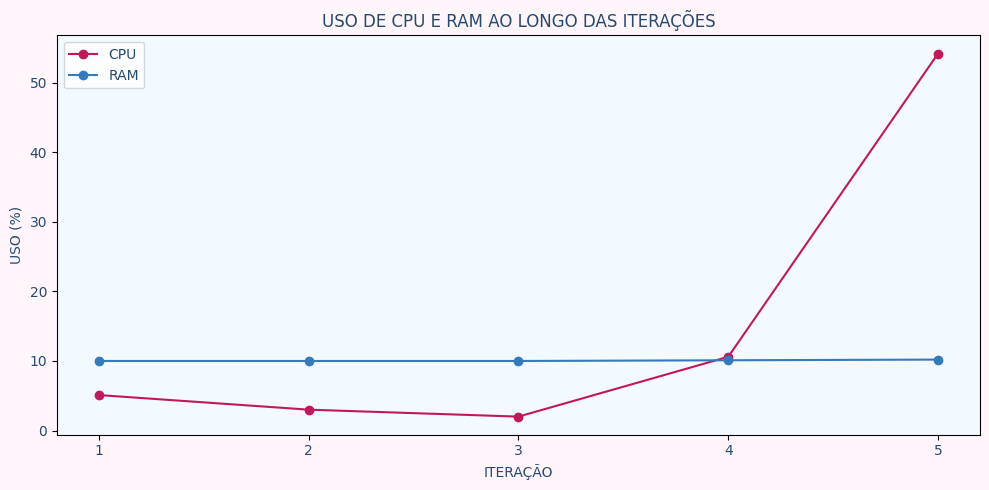

In [7]:
# AULA 12 | ATIVIDADE 03 | Coleta de Métricas de Hardware

# Requisitos:
# *Crie scripts em Python que executem as etapas a seguir:

import matplotlib.pyplot as plt
import pandas as pd

# Etapa 1:
# Efetue a ingestão do arquivo telemetria_sistema.csv utilizando a biblioteca pandas (pd.read_csv()).

telemetria = pd.read_csv("telemetria_sistema.csv")

coluna_cpu = "Uso_CPU_Pct"
coluna_ram = "Uso_RAM_Pct"

# Etapa 2:
# Calcule as médias aritméticas do consumo de CPU e RAM, imprimindo um resumo descritivo no console.

media_cpu = telemetria[coluna_cpu].mean()
media_ram = telemetria[coluna_ram].mean()

print("📋 RESUMO DA TELEMETRIA\n")
print(f"Quantidade de medições: {len(telemetria)}")
print(f"Consumo médio de CPU: {media_cpu:.2f}")
print(f"Consumo médio de RAM: {media_ram:.2f}")
print()

# Etapa 3:
# Desenvolva um gráfico de linha utilizando matplotlib para exibir as curvas de variação do uso de CPU e RAM ao longo das iterações.

iteracoes = telemetria["Iteracao"]

figura, eixo = plt.subplots(figsize=(10, 5))
figura.patch.set_facecolor("#FFF5FA")
eixo.set_facecolor("#F3FAFF")

azul_texto = "#244A73"

eixo.plot(iteracoes, telemetria[coluna_cpu], color="#C2185B", marker="o", label="CPU")
eixo.plot(iteracoes, telemetria[coluna_ram], color="#357ABD", marker="o", label="RAM")

eixo.set_title("USO DE CPU E RAM AO LONGO DAS ITERAÇÕES", color=azul_texto)
eixo.set_xlabel("ITERAÇÃO", color=azul_texto)
eixo.set_ylabel("USO (%)", color=azul_texto)
eixo.set_xticks(iteracoes)
eixo.tick_params(axis="both", labelcolor=azul_texto)
eixo.legend(labelcolor=azul_texto)

figura.tight_layout()
plt.show()